
# BCCD: подсчёт клеток и OOD-детекция

## Задачи
1. Анализ и визуализация датасета BCCD  
2. Подсчёт клеток:
   - регрессией (ResNet50)
   - детекцией (YOLO)
3. OOD-детекция для:
   - blur
   - noise
   - изображений вне распределения


In [1]:

!pip install ultralytics -q



[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: pip install --upgrade pip


## Импорты

In [2]:

import os
import cv2
import glob
import torch
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

from torchvision import models, transforms
from torch import nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image

from ultralytics import YOLO


## Пути к датасету

In [5]:
IMG_DIR = 'BCCD_Dataset-master/BCCD/JPEGImages'
ANN_DIR = 'BCCD_Dataset-master/BCCD/Annotations'


## Анализ датасета

In [6]:

images = glob.glob(os.path.join(IMG_DIR, '*.jpg'))
print('Количество изображений:', len(images))

sample = cv2.imread(images[0])
print('Размер изображения:', sample.shape)


Количество изображений: 364
Размер изображения: (480, 640, 3)


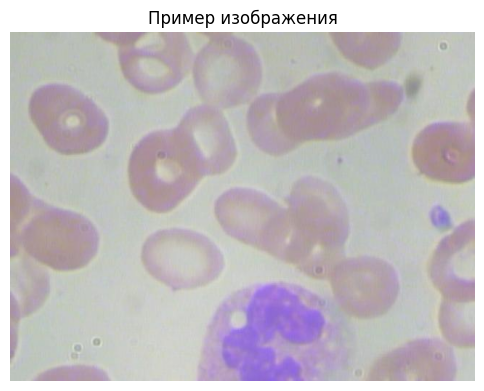

In [7]:

sample_img = cv2.cvtColor(cv2.imread(images[0]), cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(sample_img)
plt.title('Пример изображения')
plt.axis('off')
plt.show()


## Подготовка targets для регрессии

In [8]:

import xml.etree.ElementTree as ET

records = []

for xml_file in glob.glob(os.path.join(ANN_DIR, '*.xml')):
    tree = ET.parse(xml_file)
    root = tree.getroot()

    counts = {'RBC':0, 'WBC':0, 'Platelets':0}

    for obj in root.findall('object'):
        cls = obj.find('name').text
        if cls in counts:
            counts[cls] += 1

    filename = root.find('filename').text

    records.append({
        'image': os.path.join(IMG_DIR, filename),
        'RBC': counts['RBC'],
        'WBC': counts['WBC'],
        'Platelets': counts['Platelets']
    })

df = pd.DataFrame(records)
df.head()


,image,RBC,WBC,Platelets
0,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,10,1,1
1,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,13,1,1
2,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,10,1,2
3,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,16,1,1
4,BCCD_Dataset-master/BCCD/JPEGImages/BloodImage...,10,1,2


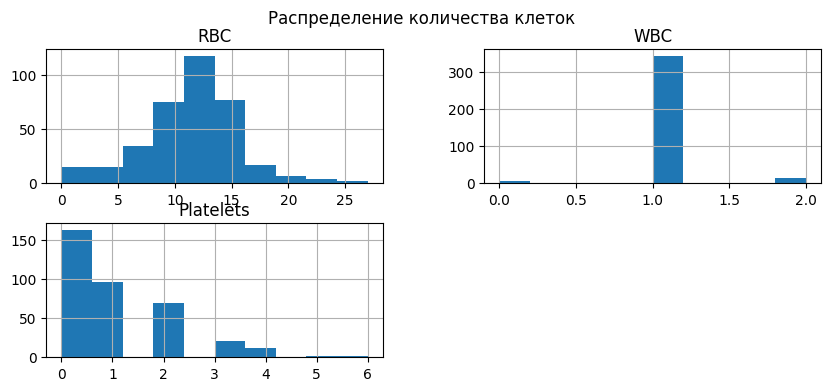

In [9]:

df[['RBC','WBC','Platelets']].hist(figsize=(10,4))
plt.suptitle('Распределение количества клеток')
plt.show()


## Dataset для ResNet50

In [10]:

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

class BloodDataset(Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row['image']).convert('RGB')
        image = transform(image)

        target = torch.tensor(
            [row['RBC'], row['WBC'], row['Platelets']],
            dtype=torch.float32
        )

        return image, target


## Обучение ResNet50

In [15]:

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

train_loader = DataLoader(BloodDataset(train_df), batch_size=8, shuffle=True)
test_loader = DataLoader(BloodDataset(test_df), batch_size=8)

model = models.resnet50(weights='DEFAULT')
model.fc = nn.Linear(model.fc.in_features, 3)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = model.to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(15):
    model.train()

    total_loss = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()

        pred = model(x)
        loss = criterion(pred, y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f'Epoch {epoch+1}:', total_loss)


Epoch 1: 1350.8221035003662
Epoch 2: 418.55358600616455
Epoch 3: 136.20831114053726
Epoch 4: 112.71051597595215
Epoch 5: 92.07155403494835
Epoch 6: 67.75462359189987
Epoch 7: 78.11642330884933
Epoch 8: 57.685282438993454
Epoch 9: 47.75723811984062
Epoch 10: 46.96703368425369
Epoch 11: 39.57611760497093
Epoch 12: 38.10111653804779
Epoch 13: 25.53867268562317
Epoch 14: 32.86010302603245
Epoch 15: 28.65519706904888


## Оценка регрессии

In [16]:

model.eval()

preds = []
targets = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        pred = model(x).cpu().numpy()

        preds.extend(pred)
        targets.extend(y.numpy())

preds = np.array(preds)
targets = np.array(targets)

print('MAE:', mean_absolute_error(targets, preds))
print('R2:', r2_score(targets, preds))


MAE: 1.530847191810608
R2: -0.10650954395532608


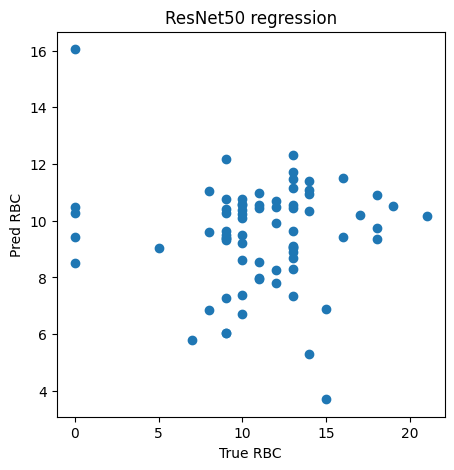

In [17]:

plt.figure(figsize=(5,5))
plt.scatter(targets[:,0], preds[:,0])
plt.xlabel('True RBC')
plt.ylabel('Pred RBC')
plt.title('ResNet50 regression')
plt.show()


## YOLO-детекция

In [20]:
import os
import glob
import random
import shutil
import xml.etree.ElementTree as ET

BASE_DIR = 'BCCD_Dataset-master/BCCD'

IMG_DIR = os.path.join(BASE_DIR, 'JPEGImages')
ANN_DIR = os.path.join(BASE_DIR, 'Annotations')

YOLO_DIR = os.path.join(BASE_DIR, 'yolo_dataset')

classes = {
    'RBC': 0,
    'WBC': 1,
    'Platelets': 2
}

for split in ['train', 'val']:
    os.makedirs(os.path.join(YOLO_DIR, 'images', split), exist_ok=True)
    os.makedirs(os.path.join(YOLO_DIR, 'labels', split), exist_ok=True)

images = glob.glob(os.path.join(IMG_DIR, '*.jpg'))
random.shuffle(images)

split_idx = int(len(images) * 0.8)

train_imgs = images[:split_idx]
val_imgs = images[split_idx:]

In [25]:
def convert_annotation(xml_file, label_file):

    tree = ET.parse(xml_file)
    root = tree.getroot()

    size = root.find('size')

    w = int(size.find('width').text)
    h = int(size.find('height').text)

    with open(label_file, 'w') as f:

        for obj in root.findall('object'):

            cls = obj.find('name').text

            if cls not in classes:
                continue

            cls_id = classes[cls]

            xmlbox = obj.find('bndbox')

            xmin = int(xmlbox.find('xmin').text)
            xmax = int(xmlbox.find('xmax').text)
            ymin = int(xmlbox.find('ymin').text)
            ymax = int(xmlbox.find('ymax').text)

            x_center = ((xmin + xmax) / 2) / w
            y_center = ((ymin + ymax) / 2) / h

            box_w = (xmax - xmin) / w
            box_h = (ymax - ymin) / h

            f.write(
                f"{cls_id} {x_center} {y_center} {box_w} {box_h}\n"
            )

In [26]:
def process_split(image_list, split):

    for img_path in image_list:

        filename = os.path.basename(img_path)

        xml_path = os.path.join(
            ANN_DIR,
            filename.replace('.jpg', '.xml')
        )

        label_path = os.path.join(
            YOLO_DIR,
            'labels',
            split,
            filename.replace('.jpg', '.txt')
        )

        convert_annotation(xml_path, label_path)

        shutil.copy(
            img_path,
            os.path.join(
                YOLO_DIR,
                'images',
                split,
                filename
            )
        )

process_split(train_imgs, 'train')
process_split(val_imgs, 'val')

In [27]:
import yaml

yaml_data = {
    'path': YOLO_DIR,
    'train': 'images/train',
    'val': 'images/val',

    'names': {
        0: 'RBC',
        1: 'WBC',
        2: 'Platelets'
    }
}

with open('blood.yaml', 'w') as f:
    yaml.dump(yaml_data, f)

print('YOLO dataset готов')

YOLO dataset готов


In [28]:
from ultralytics import YOLO

model_yolo = YOLO('yolov8n.pt')

model_yolo.train(
    data='blood.yaml',
    epochs=5,
    imgsz=640
)

Ultralytics 8.4.51 🚀 Python-3.13.3 torch-2.11.0 CPU (Apple M3)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=blood.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-6, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x13d17a0f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

## Подсчёт клеток через YOLO

In [29]:

results = model_yolo.predict(images[0])

result = results[0]

counts = Counter(result.boxes.cls.cpu().numpy())

print('Detected counts:', counts)



image 1/1 /Users/maryc/university/PythonProject/инструменты анализа данных/2 sem/3-8 task/BCCD_Dataset-master/BCCD/JPEGImages/BloodImage_00343.jpg: 480x640 20 RBCs, 1 WBC, 27.4ms
Speed: 0.5ms preprocess, 27.4ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)
Detected counts: Counter({np.float32(0.0): 20, np.float32(1.0): 1})


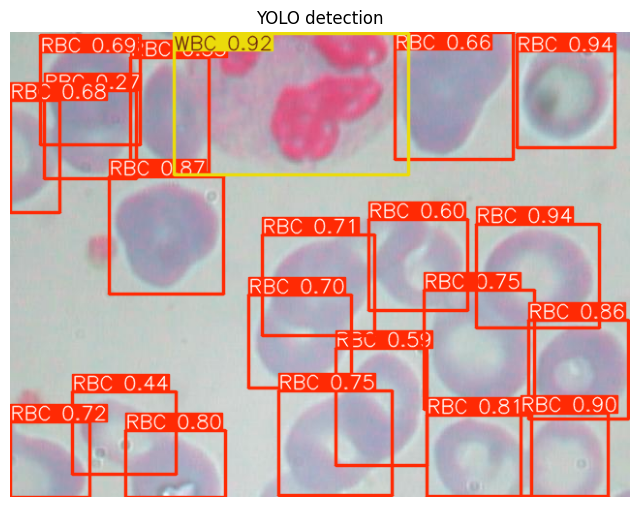

In [30]:

img = result.plot()

plt.figure(figsize=(8,8))
plt.imshow(img)
plt.axis('off')
plt.title('YOLO detection')
plt.show()


## OOD-детекция

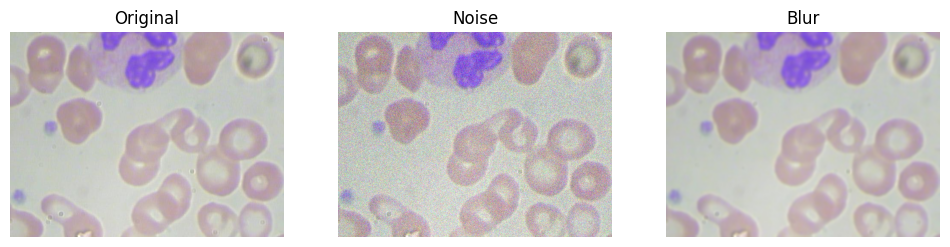

In [31]:

def add_noise(img):
    noise = np.random.normal(0, 25, img.shape)
    noisy = np.clip(img + noise, 0, 255).astype(np.uint8)
    return noisy

def blur(img):
    return cv2.GaussianBlur(img, (11,11), 0)

img = cv2.cvtColor(cv2.imread(images[0]), cv2.COLOR_BGR2RGB)

noisy = add_noise(img)
blurred = blur(img)

fig, ax = plt.subplots(1,3, figsize=(12,4))

ax[0].imshow(img)
ax[0].set_title('Original')

ax[1].imshow(noisy)
ax[1].set_title('Noise')

ax[2].imshow(blurred)
ax[2].set_title('Blur')

for a in ax:
    a.axis('off')

plt.show()



## Вывод

- ResNet50 позволяет напрямую предсказывать количество клеток
- YOLO выполняет подсчёт через детекцию объектов
- YOLO лучше интерпретируется визуально
- OOD-детекция показывает устойчивость модели к шуму и blur
